# 03 · 观测器与 Kalman 滤波：给控制器补上看不见的速度

现在去掉“控制器能直接读取真实速度”的假设。只测位置，且位置带有噪声。我们先用无噪声观测器说明可观性，再用 Kalman 滤波融合模型预测与测量，最后连接 LQR，并处理恒定外力造成的偏差。

**学习成果：** 写出预测—校正时序；理解过程噪声与测量噪声的区别；读懂 LQG 的分离原理及适用条件；用积分增广处理常值扰动。


[00 学习地图与小车建模](00_学习地图与小车建模.ipynb) · [01 经典控制与PID](01_经典控制与PID.ipynb) · [02 状态空间与LQR](02_状态空间与LQR.ipynb) · [03 观测器与Kalman滤波](03_观测器与Kalman滤波.ipynb) · [04 从有限时域优化到MPC](04_从有限时域优化到MPC.ipynb) · [05 综合实验与进阶路线](05_综合实验与进阶路线.ipynb)

每篇可独立运行；本篇内按顺序执行。图中英文标签对应正文中文术语，避免依赖本机中文字体。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, linalg

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
DT = 0.1
MASS, DRAG = 1.0, 0.4
C = np.array([[1.0, 0.0]])

def model(mass=MASS, drag=DRAG):
    Ac = np.array([[0.0, 1.0], [0.0, -drag / mass]])
    Bc = np.array([[0.0], [1.0 / mass]])
    A, B, _, _, _ = signal.cont2discrete((Ac, Bc, C, np.zeros((1, 1))), DT)
    return A, B

A, B = model()
b = B[:, 0]
REF = np.array([1.0, 0.0])

def rollout(policy, steps=120, x0=(0.0, 0.0), disturbance=None, plant=None):
    Ap, Bp = (A, B) if plant is None else plant
    xs, us = [np.array(x0, dtype=float)], []
    for k in range(steps):
        u = float(policy(xs[-1].copy(), k))
        d = 0.0 if disturbance is None else float(disturbance(k))
        xs.append(Ap @ xs[-1] + Bp[:, 0] * (u + d))
        us.append(u)
    return np.asarray(xs), np.asarray(us)

def plot_runs(runs, title, wall=None):
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    for label, (xs, us) in runs.items():
        axes[0].plot(np.arange(len(xs))*DT, xs[:, 0], label=label)
        axes[1].plot(np.arange(len(xs))*DT, xs[:, 1], label=label)
        axes[2].step(np.arange(len(us))*DT, us, where="post", label=label)
    axes[0].axhline(REF[0], color="black", ls=":", label="target")
    if wall is not None:
        axes[0].axhline(wall, color="firebrick", ls="--", label="position limit")
    for ax, label in zip(axes, ["position [m]", "velocity [m/s]", "force [N]"]):
        ax.set_ylabel(label)
    axes[0].legend(ncol=3, fontsize=8)
    axes[-1].set_xlabel("time [s]")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [2]:
Q = np.diag([20.0, 2.0])
R = np.array([[0.5]])
P = linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.solve(R + B.T @ P @ B, B.T @ P @ A)


## 1. 直接差分为什么会抖？

位置测量 $y_k=p_k+n_k$，$n_k$ 独立、方差为 $\sigma_y^2$。差分测速：

$$\tilde v_k=\frac{y_k-y_{k-1}}{T_s}.$$

噪声差分方差是 $2\sigma_y^2/T_s^2$。当 $\sigma_y=0.02\,\mathrm m,T_s=0.1\,\mathrm s$ 时，速度噪声标准差约为 $0.283\,\mathrm{m/s}$。位置看起来只有 2 cm 噪声，速度估计却很不稳定。

此外差分估计的是上个间隔平均速度，不是瞬时速度；缩短采样周期不能自动解决噪声问题。


In [3]:
sigma_y = 0.02
print("Finite-difference noise std:", np.sqrt(2)*sigma_y/DT, "m/s")


Finite-difference noise std: 0.282842712474619 m/s


## 2. Luenberger 观测器：用模型补缺测状态

采用一步预测型观测器：

$$\hat x_{k+1}=A\hat x_k+Bu_k+L(y_k-C\hat x_k).$$

若模型准确且无噪声，估计误差 $\tilde x_k=x_k-\hat x_k$ 满足：

$$\tilde x_{k+1}=(A-LC)\tilde x_k.$$

这与状态反馈形式对偶：极点配置作用于 $(A^T,C^T)$，再转置得到 L。观测器极点更快会更快消除初始估计误差，但过快也更容易放大噪声。


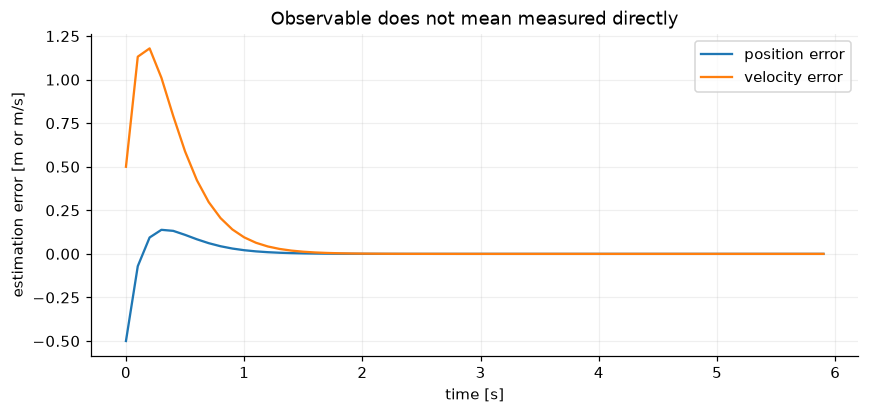

In [4]:
L = signal.place_poles(A.T, C.T, [0.55, 0.65]).gain_matrix.T
x = np.array([0.0, 0.0])
xhat = np.array([0.5, -0.5])
errors = []
for k in range(60):
    y = (C@x).item()
    u = 0.2*np.sin(0.1*k)
    errors.append(x-xhat)
    xhat = A@xhat + b*u + L[:, 0]*(y-(C@xhat).item())
    x = A@x+b*u
errors = np.asarray(errors)
assert np.linalg.norm(errors[-1]) < 1e-8
plt.plot(np.arange(len(errors))*DT, errors[:, 0], label="position error")
plt.plot(np.arange(len(errors))*DT, errors[:, 1], label="velocity error")
plt.xlabel("time [s]")
plt.ylabel("estimation error [m or m/s]")
plt.legend()
plt.title("Observable does not mean measured directly")
plt.show()


## 3. Kalman 滤波：根据不确定性选择校正量

引入随机模型：

$$x_{k+1}=Ax_k+Bu_k+w_k,\quad y_k=Cx_k+n_k,$$
$$\operatorname{Cov}(w_k)=W,\quad\operatorname{Var}(n_k)=V.$$

$W$ 描述离散过程噪声或模型预测不确定性，$V$ 描述传感器噪声。它们不同于 LQR 的代价权重 Q、R。

在线性、白噪声、相互独立且已知协方差条件下，Kalman 滤波给出最优线性最小均方误差估计；联合 Gaussian 条件下也是条件均值。恒定未知外力不属于零均值白噪声，不能仅靠“调大 W”就获得消除静差的理论保证。

### 明确时序

这里 $\hat x_k^-$ 是测量之前的先验，$\hat x_k^+$ 是测量之后的后验：

$$S_k=C\Sigma_k^-C^T+V,\quad L_k=\Sigma_k^-C^TS_k^{-1},$$
$$\hat x_k^+=\hat x_k^-+L_k(y_k-C\hat x_k^-),$$
$$\Sigma_k^+=(I-L_kC)\Sigma_k^-(I-L_kC)^T+L_kVL_k^T,$$
$$\hat x_{k+1}^-=A\hat x_k^++Bu_k,\quad\Sigma_{k+1}^-=A\Sigma_k^+A^T+W.$$

协方差使用 Joseph 形式，减少数值舍入对对称性和半正定性的影响。控制输入在后验更新之后计算，再预测下一步；不要在控制器中偷用下一时刻的测量。


Velocity RMSE: difference=0.2930, Kalman=0.0355 m/s


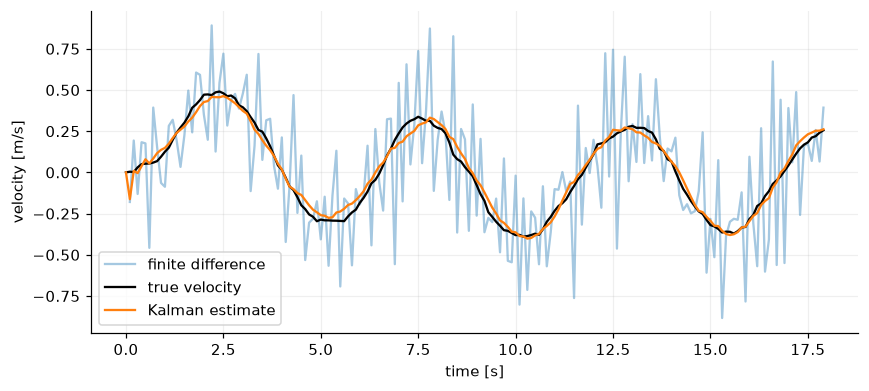

In [5]:
W = np.diag([1e-7, 2e-4])
V = sigma_y**2

def correct(prior, cov, measurement):
    innovation = measurement - (C@prior).item()
    S = (C@cov@C.T).item()+V
    gain = cov@C.T/S
    posterior = prior + gain[:, 0]*innovation
    ILC = np.eye(2)-gain@C
    postcov = ILC@cov@ILC.T + V*gain@gain.T
    return posterior, postcov

rng = np.random.default_rng(7)
steps = 180
truth = np.zeros((steps+1, 2))
measurements, estimates, covariances = [], [], []
prior, cov = np.zeros(2), np.diag([0.1, 1.0])
for k in range(steps):
    y = truth[k, 0]+rng.normal(0, sigma_y)
    post, postcov = correct(prior, cov, y)
    u = 0.4*np.sin(0.12*k)
    measurements.append(y)
    estimates.append(post)
    covariances.append(postcov)
    truth[k+1] = A@truth[k]+b*u+rng.multivariate_normal(np.zeros(2), W)
    prior, cov = A@post+b*u, A@postcov@A.T+W
measurements, estimates = np.asarray(measurements), np.asarray(estimates)
fd = np.r_[np.nan, np.diff(measurements)/DT]
# Discard initialization when comparing stationary estimation quality.
idx = slice(20, None)
rmse_fd = np.sqrt(np.mean((fd[idx]-truth[:-1, 1][idx])**2))
rmse_kf = np.sqrt(np.mean((estimates[idx, 1]-truth[:-1, 1][idx])**2))
print(f"Velocity RMSE: difference={rmse_fd:.4f}, Kalman={rmse_kf:.4f} m/s")
assert rmse_kf < rmse_fd
assert np.min(np.linalg.eigvalsh(np.asarray(covariances))) >= -1e-12
t = np.arange(steps)*DT
plt.plot(t, fd, alpha=0.4, label="finite difference")
plt.plot(t, truth[:-1, 1], color="black", label="true velocity")
plt.plot(t, estimates[:, 1], label="Kalman estimate")
plt.xlabel("time [s]")
plt.ylabel("velocity [m/s]")
plt.legend()
plt.show()


### 读图时把两个问题分开

看蓝色抖动变小，只能说明这一组模型、噪声与参数下速度估计更准确。还要问估计是否迟滞、协方差是否符合实际误差、创新是否有偏。创新持续同向，常提示模型遗漏了偏置或外力。

## 4. LQG：先估计，再反馈

把 LQR 中的真状态替换为后验估计：$u_k=-K(\hat x_k^+-x_r)$。在线性、无约束且满足标准噪声假设的问题中，这组成 LQG（Linear Quadratic Gaussian）控制。

**分离原理：** 稳定状态反馈与稳定观测器可分别设计；在线性模型的联合误差坐标下，闭环矩阵是分块三角形式，其特征值来自控制器和估计器两部分。约束、饱和、模型失配之后，不能直接据此宣称整个系统仍有同样保证。

下例只给测量加噪声，物理对象没有额外过程噪声；W 在此代表设计者对预测可信度的设定。没有限制输入，保留 LQG 结构。


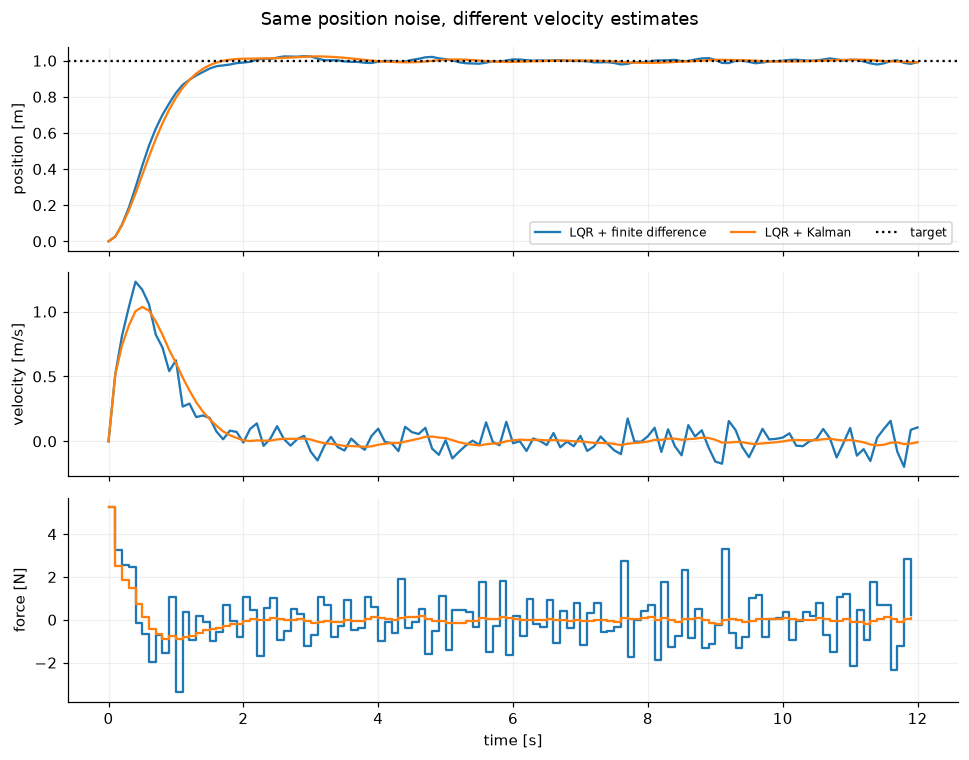

LQR + finite difference input increment RMS: 1.8079239099032665
LQR + Kalman input increment RMS: 0.29353788271297837


In [6]:
rng = np.random.default_rng(11)
noise = rng.normal(0, sigma_y, 120)
prior, cov = np.zeros(2), np.diag([0.1, 1.0])
previous_y = 0.0

def lqg(x, k):
    global prior, cov
    post, postcov = correct(prior, cov, x[0]+noise[k])
    u = -(K@(post-REF)).item()
    prior, cov = A@post+b*u, A@postcov@A.T+W
    return u

def differenced_feedback(x, k):
    global previous_y
    y = x[0]+noise[k]
    vhat = 0.0 if k == 0 else (y-previous_y)/DT
    previous_y = y
    return -(K@(np.array([y, vhat])-REF)).item()

noisy_runs = {"LQR + finite difference": rollout(differenced_feedback),
              "LQR + Kalman": rollout(lqg)}
plot_runs(noisy_runs, "Same position noise, different velocity estimates")
for name, (xs, us) in noisy_runs.items():
    print(name, "input increment RMS:", np.sqrt(np.mean(np.diff(us)**2)))


## 5. 估计得更准，也不自动消除恒定外力

LQR 对常值目标的设计使用 $u_r=0$。若实际存在外力 $d$，正确平衡输入是 $-d$，普通状态反馈要靠偏移位置产生这一输入。即使真状态完全已知，问题仍然存在。

一种方法是把积分器作为状态加入：

$$z_{k+1}=z_k+T_s(p_k-r),$$
$$\begin{bmatrix}e_{k+1}\\z_{k+1}\end{bmatrix}
=\underbrace{\begin{bmatrix}A&0\\T_sC&1\end{bmatrix}}_{A_a}
\begin{bmatrix}e_k\\z_k\end{bmatrix}
+\underbrace{\begin{bmatrix}B\\0\end{bmatrix}}_{B_a}u_k.$$

对增广系统做 LQR 就得到 LQI（Linear Quadratic Integral）。这里积分的是“实际减目标”，控制仍采用负反馈。下面使用真状态、无输入饱和，单独验证常值外力消除；如果加入执行器约束，还需要处理积分饱和。


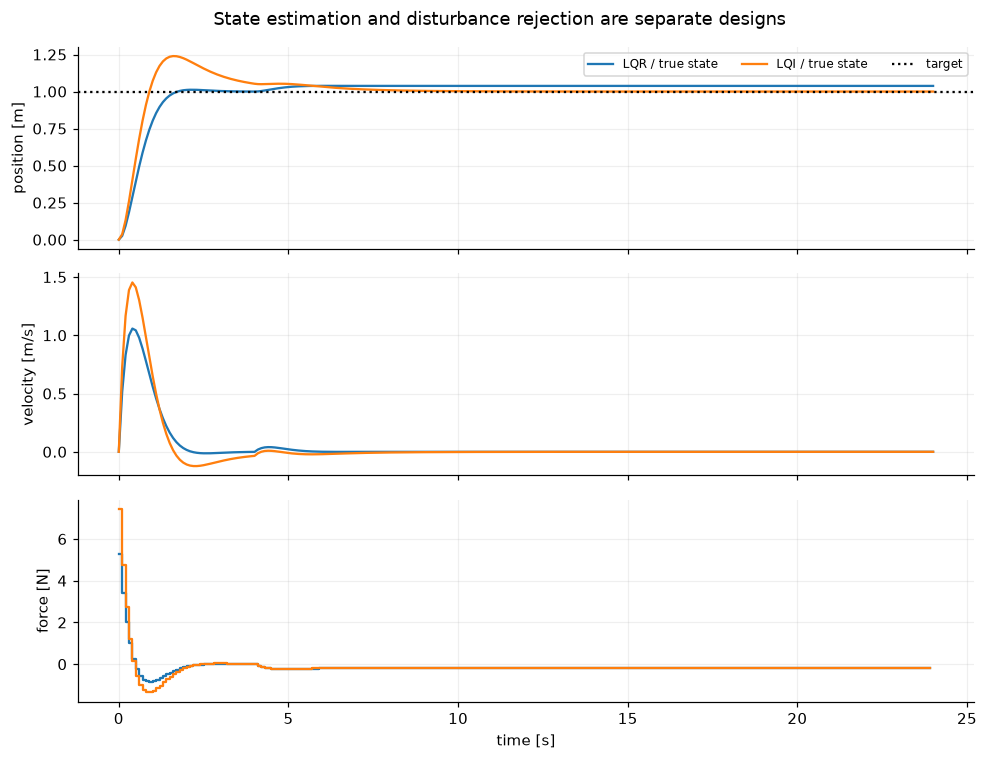

LQR / true state: final position=1.038033, force=-0.200000
LQI / true state: final position=1.000000, force=-0.200000


In [7]:
Aa = np.block([[A, np.zeros((2, 1))], [DT*C, np.ones((1, 1))]])
Ba = np.vstack([B, [[0.0]]])
Qa = np.diag([20.0, 2.0, 8.0])
Pa = linalg.solve_discrete_are(Aa, Ba, Qa, R)
Ka = np.linalg.solve(R+Ba.T@Pa@Ba, Ba.T@Pa@Aa)
assert np.max(np.abs(np.linalg.eigvals(Aa-Ba@Ka))) < 1
z = 0.0

def lqi(x, k):
    global z
    u = -(Ka@np.r_[x-REF, z]).item()
    z += DT*(x[0]-REF[0])
    return u

wind = lambda k: 0.2 if k >= 40 else 0.0
integral_runs = {
    "LQR / true state": rollout(lambda x, k: -(K@(x-REF)).item(), steps=240, disturbance=wind),
    "LQI / true state": rollout(lqi, steps=240, disturbance=wind),
}
plot_runs(integral_runs, "State estimation and disturbance rejection are separate designs")
for name, (xs, us) in integral_runs.items():
    print(f"{name}: final position={xs[-1, 0]:.6f}, force={us[-1]:.6f}")
assert abs(integral_runs["LQI / true state"][0][-1, 0]-1) < 1e-4


## 6. 通向 offset-free MPC 的另一座桥

还可以把未知常值外力建模为慢变状态：

$$\begin{bmatrix}x_{k+1}\\d_{k+1}\end{bmatrix}
=\begin{bmatrix}A&B\\0&1\end{bmatrix}
\begin{bmatrix}x_k\\d_k\end{bmatrix}
+\begin{bmatrix}B\\0\end{bmatrix}u_k+\text{过程噪声},\quad
y_k=[C\ \ 0]\begin{bmatrix}x_k\\d_k\end{bmatrix}+n_k.$$

估计到 $\hat d$ 后，解稳态目标：

$$x_s=Ax_s+B(u_s+\hat d),\quad Cx_s=r.$$

本例得到 $x_s=[r,0]^T,u_s=-\hat d$。再让优化器围绕这个平衡点优化。要同时检查增广系统可检测性、目标可行性和估计收敛；若 $|\hat d|>1$，执行器根本不能维持静止。

这给出从积分控制到无静差 MPC 的原理连接；默认代码实现到 LQI，扰动增广 MPC 留给第 05 篇的研究任务。

### 自测

1. 为什么“每步都重新优化”仍可能有稳态偏差？
2. V 增大、W 不变时，滤波器通常更信任谁？
3. 若把 $C$ 改为只量速度，Kalman 是否会凭算法恢复绝对位置？
4. 控制器用的是 $\hat x_k^+$ 还是 $\hat x_{k+1}^-$？

<details><summary>参考思路</summary>

1. 每次都可能用同一个有偏模型和错误稳态输入。2. 测量更不可信，通常相对更依赖模型。3. 不能，可观性决定信息是否存在。4. 当前测量更新后的 $\hat x_k^+$；计算 u 后才预测下一步。

</details>
